<a href="https://colab.research.google.com/github/magenta/ddsp/blob/main/ddsp/colab/demos/timbre_transfer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##### Copyright 2021 Google LLC.

Licensed under the Apache License, Version 2.0 (the "License");





In [1]:
# Copyright 2026 Google LLC. All Rights Reserved.

# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at

#     http://www.apache.org/licenses/LICENSE-2.0

# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.
# ==============================================================================

# DDSP Timbre Transfer Demo

This notebook is a demo of timbre transfer using DDSP (Differentiable Digital Signal Processing).
The model here is trained to generate audio conditioned on a time series of fundamental frequency and loudness.

* [DDSP ICLR paper](https://openreview.net/forum?id=B1x1ma4tDr)
* [Audio Examples](http://goo.gl/magenta/ddsp-examples)

This notebook extracts these features from input audio (either uploaded files, or recorded from the microphone) and resynthesizes with the model.

<img src="https://magenta.tensorflow.org/assets/ddsp/ddsp_cat_jamming.png" alt="DDSP Tone Transfer" width="700">



By default, the notebook will download pre-trained models. You can train a model on your own sounds by using the [Train Autoencoder Colab](https://github.com/magenta/ddsp/blob/main/ddsp/colab/demos/train_autoencoder.ipynb).

Have fun! And please feel free to hack this notebook to make your own creative interactions.


### Instructions for running:

* Make sure to use a GPU runtime, click:  __Runtime >> Change Runtime Type >> GPU__
* Press ▶️ on the left of each of the cells
* View the code: Double-click any of the cells
* Hide the code: Double click the right side of the cell





In [2]:
#@title # Step 1: Install DDSP

#@markdown Install DDSP in a Python 3.9 conda environment.
#@markdown Package installation is separated into stages for compatibility
#@markdown with the legacy DDSP 3.7.0 / CREPE dependencies.

# ---------------------------------------------------------
# Create clean Python 3.9 Miniconda environment
# ---------------------------------------------------------

!rm -rf /content/miniconda

!curl -L https://repo.anaconda.com/miniconda/Miniconda3-py39_23.11.0-2-Linux-x86_64.sh \
    -o /content/miniconda.sh

!chmod +x /content/miniconda.sh
!/content/miniconda.sh -b -p /content/miniconda

!sudo apt-get update -qq
!sudo apt-get install -y libportaudio2 libsndfile1

# CUDA libraries used by the original notebook
!/content/miniconda/bin/conda install -y \
    -c conda-forge \
    cudatoolkit=11.2 \
    cudnn=8.1


PYTHON = "/content/miniconda/bin/python"


# ---------------------------------------------------------
# Packaging tools
# ---------------------------------------------------------

!{PYTHON} -m pip install \
    "pip==23.3.2" \
    "setuptools==68.2.2" \
    wheel


# ---------------------------------------------------------
# Install TensorFlow first
# ---------------------------------------------------------

!{PYTHON} -m pip install \
    "numpy==1.23.5" \
    "scipy==1.10.1" \
    "protobuf==3.19.6" \
    "tensorflow==2.11.0" \
    "tensorflow-probability==0.19.0"


# ---------------------------------------------------------
# CREPE dependencies
# ---------------------------------------------------------

!{PYTHON} -m pip install \
    "h5py<4" \
    imageio \
    matplotlib \
    scikit-learn \
    resampy \
    "hmmlearn==0.2.7"


# Install legacy CREPE separately
!{PYTHON} -m pip install \
    --no-build-isolation \
    --no-deps \
    "crepe==0.0.12"


# ---------------------------------------------------------
# Dependencies required by DDSP training/inference
# ---------------------------------------------------------

!{PYTHON} -m pip install \
    absl-py \
    "gin-config>=0.3.0" \
    "cloudml-hypertune==0.1.0.dev6" \
    google-cloud-storage \
    "dill<=0.3.4" \
    future \
    "librosa<=0.10" \
    "pydub<=0.25.1" \
    "mir_eval<=0.7" \
    "note_seq<0.0.4" \
    six \
    "tensorflow-datasets==4.9.0"


# ---------------------------------------------------------
# Install DDSP without making pip solve the legacy
# dependency chain again
# ---------------------------------------------------------

!{PYTHON} -m pip install \
    --no-deps \
    "ddsp==3.7.0"


# ---------------------------------------------------------
# Verify the environment
# ---------------------------------------------------------

!{PYTHON} -c "\
import numpy as np; \
import tensorflow as tf; \
import tensorflow_probability as tfp; \
import crepe; \
import ddsp; \
import ddsp.training; \
import gin; \
import librosa; \
print('NumPy:', np.__version__); \
print('TensorFlow:', tf.__version__); \
print('TensorFlow Probability:', tfp.__version__); \
print('DDSP:', ddsp.__version__); \
print('CREPE import: OK'); \
print('ddsp.training import: OK'); \
print('ENVIRONMENT OK')"

print('\nDone installing DDSP environment!')

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  125M  100  125M    0     0   179M      0 --:--:-- --:--:-- --:--:--  179M
PREFIX=/content/miniconda
Unpacking payload ...
                                                                            
Installing base environment...





Preparing transaction: - \ | / - done
Executing transaction: | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | done
installation finished.
    You currently have a PYTHONPATH environment variable set. This may cause
    unexpected behavior when running the Python interpreter in Miniconda3.
    For best results, please verify that your PYTHONPATH only points to
    directories of packages that are compatible with the Python interpreter
    in Miniconda3: /content/miniconda
W: Skipping acquire of configured file 'main/sour

In [3]:
PYTHON = "/content/miniconda/bin/python"

# Remove the newer TFDS dependency chain that upgraded protobuf
!{PYTHON} -m pip uninstall -y \
    array-record \
    tensorflow-datasets \
    tensorflow-metadata

# Use versions from the TensorFlow 2.11 / DDSP 3.7 era
!{PYTHON} -m pip install \
    "tensorflow-datasets==4.8.3" \
    "tensorflow-metadata==1.12.0"

# Force protobuf back to the TensorFlow 2.11-compatible version
!{PYTHON} -m pip install \
    --force-reinstall \
    --no-deps \
    "protobuf==3.19.6"

# Proper verification
verify_code = """
import numpy as np
import scipy
import tensorflow as tf
import tensorflow_probability as tfp
import crepe
import ddsp
import ddsp.training
import gin
import librosa

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("TensorFlow:", tf.__version__)
print("TFP:", tfp.__version__)
print("DDSP:", ddsp.__version__)
print("CREPE: OK")
print("ddsp.training: OK")
print("ENVIRONMENT OK")
"""

with open("/content/verify_ddsp.py", "w") as f:
    f.write(verify_code)

!{PYTHON} /content/verify_ddsp.py

Found existing installation: array_record 0.5.1
Uninstalling array_record-0.5.1:
  Successfully uninstalled array_record-0.5.1
Found existing installation: tensorflow-datasets 4.9.0
Uninstalling tensorflow-datasets-4.9.0:
  Successfully uninstalled tensorflow-datasets-4.9.0
Found existing installation: tensorflow-metadata 1.17.3
Uninstalling tensorflow-metadata-1.17.3:
  Successfully uninstalled tensorflow-metadata-1.17.3
  Using cached protobuf-3.20.3-cp39-cp39-manylinux_2_5_x86_64.manylinux1_x86_64.whl.metadata (679 bytes)
INFO: pip is looking at multiple versions of googleapis-common-protos to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 51.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.3/52.3 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.5/126.5 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 297.6/297.6 kB 30.2 MB/s eta

In [4]:
PYTHON = "/content/miniconda/bin/python"

# CREPE needs TensorFlow to already exist.
# TensorFlow 2.11 is now installed, so install CREPE again.
!{PYTHON} -m pip install \
    --no-build-isolation \
    --no-deps \
    "crepe==0.0.12"

# Verify CREPE first
!{PYTHON} -c "import tensorflow as tf; import crepe; print('TensorFlow:', tf.__version__); print('CREPE: OK')"

  Using cached crepe-0.0.12.tar.gz (15 kB)
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.
2026-11-09 06:11:41.111029: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-09 06:11:41.229923: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dy

In [5]:
# Manual installation of legacy CREPE 0.0.12
# This bypasses its old setup.py installer.

PYTHON = "/content/miniconda/bin/python"

# ---------------------------------------------------------
# 1. Download CREPE 0.0.12 source
# ---------------------------------------------------------

!rm -rf /content/crepe-src

!git clone \
    --depth 1 \
    --branch v0.0.12 \
    https://github.com/marl/crepe.git \
    /content/crepe-src


# ---------------------------------------------------------
# 2. Download the pretrained CREPE "full" model weights
# DDSP compute_f0() uses CREPE's default full model.
# ---------------------------------------------------------

!wget -q \
    https://github.com/marl/crepe/raw/models/model-full.h5.bz2 \
    -O /content/crepe-src/crepe/model-full.h5.bz2

!bzip2 -df \
    /content/crepe-src/crepe/model-full.h5.bz2


# ---------------------------------------------------------
# 3. Copy CREPE directly into Miniconda site-packages
# ---------------------------------------------------------

SITE_PACKAGES = !{PYTHON} -c "import site; print(site.getsitepackages()[0])"
SITE_PACKAGES = SITE_PACKAGES[0].strip()

print("Installing CREPE into:")
print(SITE_PACKAGES)

!rm -rf "{SITE_PACKAGES}/crepe"
!cp -r /content/crepe-src/crepe "{SITE_PACKAGES}/crepe"


# ---------------------------------------------------------
# 4. Verify CREPE itself
# ---------------------------------------------------------

!{PYTHON} -c "import crepe; print('CREPE import: OK'); print(crepe.__file__)"

Cloning into '/content/crepe-src'...
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 18 (delta 0), reused 9 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (18/18), 341.93 KiB | 1.42 MiB/s, done.
Note: switching to 'a666a03011a9cdab70e9abd0b5009ad60c5f8926'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

Installing CREPE into:
/content/miniconda/lib/python3.9/site-packages
CREPE import: OK
/content/miniconda/lib/pyth

In [6]:
PYTHON = "/content/miniconda/bin/python"

verify_code = """
import numpy as np
import scipy
import tensorflow as tf
import tensorflow_probability as tfp
import crepe
import ddsp
import ddsp.training
import gin
import librosa

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("TensorFlow:", tf.__version__)
print("TFP:", tfp.__version__)
print("DDSP:", ddsp.__version__)
print("CREPE: OK")
print("ddsp.training: OK")
print("ENVIRONMENT OK")
"""

with open("/content/verify_ddsp.py", "w") as f:
    f.write(verify_code)

!{PYTHON} /content/verify_ddsp.py

2026-11-09 06:16:39.603730: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-09 06:16:39.723664: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /usr/lib64-nvidia
2026-11-09 06:16:39.723758: I tensorflow/compiler/xla/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2026-11-09 06:16:40.771727: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared 

In [7]:
PYTHON = "/content/miniconda/bin/python"

# Match Google Cloud / protobuf packages to the TensorFlow 2.11 era.
# Use --no-deps so pip does not upgrade protobuf again.

!{PYTHON} -m pip install --force-reinstall --no-deps \
    "protobuf==3.19.6" \
    "googleapis-common-protos==1.57.0" \
    "proto-plus==1.22.2" \
    "google-api-core==2.11.0" \
    "google-cloud-core==2.3.2" \
    "google-cloud-storage==2.7.0" \
    "google-resumable-media==2.4.0"

# Verify the environment
verify_code = """
import numpy as np
import tensorflow as tf
import tensorflow_probability as tfp
import crepe
import ddsp
import ddsp.training
import ddsp.training.metrics
import ddsp.training.models

print("TensorFlow:", tf.__version__)
print("TFP:", tfp.__version__)
print("DDSP:", ddsp.__version__)
print("CREPE: OK")
print("ddsp.training: OK")
print("DDSP metrics/models: OK")
print("ENVIRONMENT OK")
"""

with open("/content/verify_ddsp.py", "w") as f:
    f.write(verify_code)

!{PYTHON} /content/verify_ddsp.py

  Using cached protobuf-3.19.6-cp39-cp39-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (787 bytes)
Using cached protobuf-3.19.6-cp39-cp39-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (1.1 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 218.0/218.0 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.9/47.9 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.3/120.3 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.2/110.2 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.4/77.4 kB 8.8 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 3.19.6
    Uninstalling protobuf-3.19.6:
      Successfully uninstalled protobuf-3.19.6
  Attempting uninstall: proto-plus
    Found existing installation: proto-plus 1.27.2
    Uninstalling proto-plus-1.27.2:
      Successfully uninstalled proto-plus-1.27.2
  Attempting uninstall: googleapis-common-protos
    Found exist

Saving Flute_E4_Reference.wav to Flute_E4_Reference.wav
Audio shape: (1, 44061), saved to /content/input_audio.npy


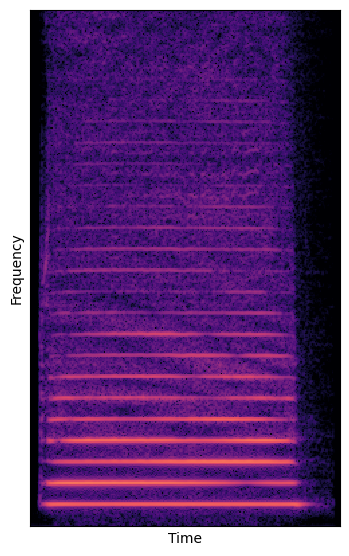

In [16]:
#@title # Step 2: Record or Upload Audio
#@markdown * Either record audio from microphone or upload audio from file (.mp3 or .wav)
#@markdown * Audio should be monophonic (single instrument / voice)

record_or_upload = "Upload (.mp3 or .wav)"  #@param ["Record", "Upload (.mp3 or .wav)"]

record_seconds =     5#@param {type:"number", min:1, max:10, step:1}

import warnings
warnings.filterwarnings("ignore")

import base64
import io
import os

import numpy as np
import matplotlib.pyplot as plt
from IPython import display
from scipy.io import wavfile

from google.colab import files as colab_files
from google.colab import output

SAMPLE_RATE = 16000


def play(array_of_floats, sample_rate=SAMPLE_RATE):
  """Play audio in colab using HTML5 audio widget."""
  if len(array_of_floats.shape) == 2:
    array_of_floats = array_of_floats[0]
  normalizer = float(np.iinfo(np.int16).max)
  array_of_ints = np.array(
      np.asarray(array_of_floats) * normalizer, dtype=np.int16)
  memfile = io.BytesIO()
  wavfile.write(memfile, sample_rate, array_of_ints)
  html = """<audio controls>
              <source controls src="data:audio/wav;base64,{base64_wavfile}"
              type="audio/wav" />
              Your browser does not support the audio element.
            </audio>"""
  html = html.format(
      base64_wavfile=base64.b64encode(memfile.getvalue()).decode('ascii'))
  memfile.close()
  display.display(display.HTML(html))


def record_audio(seconds=3, sample_rate=SAMPLE_RATE):
  """Record audio from the browser microphone."""
  record_js_code = """
  const sleep  = time => new Promise(resolve => setTimeout(resolve, time))
  const b2text = blob => new Promise(resolve => {
    const reader = new FileReader()
    reader.onloadend = e => resolve(e.srcElement.result)
    reader.readAsDataURL(blob)
  })

  var record = time => new Promise(async resolve => {
    stream = await navigator.mediaDevices.getUserMedia({ audio: true })
    recorder = new MediaRecorder(stream)
    chunks = []
    recorder.ondataavailable = e => chunks.push(e.data)
    recorder.start()
    await sleep(time)
    recorder.onstop = async ()=>{
      blob = new Blob(chunks)
      text = await b2text(blob)
      resolve(text)
    }
    recorder.stop()
  })
  """
  print('Starting recording for {} seconds...'.format(seconds))
  display.display(display.Javascript(record_js_code))
  audio_string = output.eval_js('record(%d)' % (seconds * 1000.0))
  print('Finished recording!')
  audio_bytes = base64.b64decode(audio_string.split(',')[1])
  # Convert bytes to numpy using pydub
  from pydub import AudioSegment
  segment = AudioSegment.from_file(io.BytesIO(audio_bytes))
  segment = segment.set_frame_rate(sample_rate).set_channels(1).set_sample_width(2)
  samples = np.array(segment.get_array_of_samples()).astype(np.float32)
  samples = samples / float(np.iinfo(np.int16).max)
  return samples


def upload_audio(sample_rate=SAMPLE_RATE):
  """Upload audio files and return (filenames, audio_arrays)."""
  from pydub import AudioSegment
  audio_files = colab_files.upload()
  fnames = list(audio_files.keys())
  audios = []
  for fname in fnames:
    segment = AudioSegment.from_file(io.BytesIO(audio_files[fname]))
    segment = segment.set_frame_rate(sample_rate).set_channels(1).set_sample_width(2)
    samples = np.array(segment.get_array_of_samples()).astype(np.float32)
    samples = samples / float(np.iinfo(np.int16).max)
    audios.append(samples)
  return fnames, audios


def specplot(audio, vmin=-5, vmax=1, rotate=True, size=512 + 256):
  """Plot the log magnitude spectrogram of audio."""
  if len(audio.shape) == 2:
    audio = audio[0]
  # Compute spectrogram using numpy/scipy (no ddsp needed)
  from scipy import signal as scipy_signal
  f, t, Sxx = scipy_signal.stft(audio, fs=SAMPLE_RATE, nperseg=size,
                                 noverlap=size * 3 // 4)
  logmag = np.log10(np.abs(Sxx) + 1e-7)
  if rotate:
    logmag = np.flipud(logmag)
  plt.matshow(logmag, vmin=vmin, vmax=vmax, cmap=plt.cm.magma, aspect='auto')
  plt.xticks([])
  plt.yticks([])
  plt.xlabel('Time')
  plt.ylabel('Frequency')


# --- Record or Upload ---
if record_or_upload == "Record":
  audio = record_audio(seconds=record_seconds)
else:
  filenames, audios = upload_audio()
  audio = audios[0]

if len(audio.shape) == 1:
  audio = audio[np.newaxis, :]

# Save audio for the inference script
np.save('/content/input_audio.npy', audio)
print(f'Audio shape: {audio.shape}, saved to /content/input_audio.npy')

# Plot and play
specplot(audio)
play(audio)


In [17]:
#@title # Step 4: Run Timbre Transfer

#@markdown Choose a model and adjust parameters, then run this cell.
#@markdown To try different settings, change the values and re-run this cell.

model = 'Flute' #@param ['Violin', 'Flute', 'Flute2', 'Trumpet', 'Tenor_Saxophone', 'Upload your own (checkpoint folder as .zip)']

#@markdown ---
#@markdown ## Note Detection
#@markdown You can leave this at 1.0 for most cases
threshold = 1 #@param {type:"slider", min: 0.0, max:2.0, step:0.01}

#@markdown ## Automatic Adjustments
ADJUST = False #@param{type:"boolean"}

#@markdown Quiet parts without notes detected (dB)
quiet = 20 #@param {type:"slider", min: 0, max:60, step:1}

#@markdown Force pitch to nearest note (amount)
autotune = 0 #@param {type:"slider", min: 0.0, max:1.0, step:0.1}

#@markdown ## Manual Adjustments
#@markdown Shift the pitch (octaves)
pitch_shift =  0 #@param {type:"slider", min:-2, max:2, step:1}

#@markdown Adjust the overall loudness (dB)
loudness_shift = 0 #@param {type:"slider", min:-20, max:20, step:1}

# Handle custom model upload
if model == 'Upload your own (checkpoint folder as .zip)':
  UPLOAD_DIR = '/content/uploaded'
  !mkdir -p $UPLOAD_DIR
  from google.colab import files
  uploaded_files = files.upload()
  for fnames in uploaded_files.keys():
    print("Unzipping... {}".format(fnames))
    !unzip -o "/content/$fnames" -d $UPLOAD_DIR &> /dev/null
  model_arg = 'custom'
else:
  model_arg = model

adjust_flag = 1 if ADJUST else 0


# Create and save inferencing script
SCRIPT = r'''
"""DDSP Timbre Transfer inference script.
Runs inside conda environment with Python 3.9 and ddsp==3.7.0.
Reads input audio and parameters, writes output audio and plot data.
"""
import argparse
import copy
import os
import pickle
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np

import ddsp
import ddsp.training
from ddsp.training.postprocessing import detect_notes, fit_quantile_transform
import gin
import tensorflow.compat.v2 as tf


def get_tuning_factor(f0_midi, f0_confidence, mask_on):
  """Get offset in cents to most consistent chromatic intervals."""
  tuning_factors = np.linspace(-0.5, 0.5, 101)
  midi_diffs = (f0_midi[mask_on][:, np.newaxis] -
                tuning_factors[np.newaxis, :]) % 1.0
  midi_diffs[midi_diffs > 0.5] -= 1.0
  weights = f0_confidence[mask_on][:, np.newaxis]
  cost_diffs = np.abs(midi_diffs)
  cost_diffs = np.mean(weights * cost_diffs, axis=0)
  f0_at = f0_midi[mask_on][:, np.newaxis] - midi_diffs
  f0_at_diffs = np.diff(f0_at, axis=0)
  deltas = (f0_at_diffs != 0.0).astype(float)
  cost_deltas = np.mean(weights[:-1] * deltas, axis=0)
  norm = lambda x: (x - np.mean(x)) / np.std(x)
  cost = norm(cost_deltas) + norm(cost_diffs)
  return tuning_factors[np.argmin(cost)]


def auto_tune(f0_midi, tuning_factor, mask_on, amount=0.0):
  """Reduce variance of f0 from scale intervals."""
  major_scale = np.ravel(
      [np.array([0, 2, 4, 5, 7, 9, 11]) + 12 * i for i in range(10)])
  all_scales = np.stack([major_scale + i for i in range(12)])
  f0_on = f0_midi[mask_on]
  f0_diff_tsn = (
      f0_on[:, np.newaxis, np.newaxis] - all_scales[np.newaxis, :, :])
  f0_diff_ts = np.min(np.abs(f0_diff_tsn), axis=-1)
  f0_diff_s = np.mean(f0_diff_ts, axis=0)
  scale_idx = np.argmin(f0_diff_s)
  f0_diff_tn = f0_midi[:, np.newaxis] - all_scales[scale_idx][np.newaxis, :]
  note_idx = np.argmin(np.abs(f0_diff_tn), axis=-1)
  midi_diff = np.take_along_axis(
      f0_diff_tn, note_idx[:, np.newaxis], axis=-1)[:, 0]
  return f0_midi - amount * midi_diff


def shift_ld(audio_features, ld_shift=0.0):
  audio_features['loudness_db'] += ld_shift
  return audio_features


def shift_f0(audio_features, pitch_shift=0.0):
  audio_features['f0_hz'] *= 2.0 ** (pitch_shift)
  audio_features['f0_hz'] = np.clip(audio_features['f0_hz'], 0.0,
                                    librosa.midi_to_hz(110.0))
  return audio_features


def find_model_dir(dir_name):
  for root, dirs, filenames in os.walk(dir_name):
    for filename in filenames:
      if filename.endswith(".gin") and not filename.startswith("."):
        return root
  return dir_name


def main():
  import librosa  # imported here so shift_f0 has access
  globals()['librosa'] = librosa

  parser = argparse.ArgumentParser()
  parser.add_argument('--audio_path', required=True)
  parser.add_argument('--output_dir', default='/content/output')
  parser.add_argument('--model', default='Violin')
  parser.add_argument('--threshold', type=float, default=1.0)
  parser.add_argument('--adjust', type=int, default=1)
  parser.add_argument('--quiet', type=float, default=20.0)
  parser.add_argument('--autotune', type=float, default=0.0)
  parser.add_argument('--pitch_shift', type=float, default=0.0)
  parser.add_argument('--loudness_shift', type=float, default=0.0)
  args = parser.parse_args()

  os.makedirs(args.output_dir, exist_ok=True)

  # Load audio
  audio = np.load(args.audio_path)
  print(f'Loaded audio: shape={audio.shape}')

  # --- Load Model ---
  PRETRAINED_MODELS = ['Violin', 'Flute', 'Flute2', 'Trumpet', 'Tenor_Saxophone']

  if args.model in PRETRAINED_MODELS:
    PRETRAINED_DIR = '/content/pretrained'
    os.system(f'rm -rf {PRETRAINED_DIR}')
    os.makedirs(PRETRAINED_DIR, exist_ok=True)
    GCS_CKPT_DIR = 'gs://ddsp/models/timbre_transfer_colab/2021-07-08'
    model_dir_gcs = os.path.join(GCS_CKPT_DIR, 'solo_%s_ckpt' % args.model.lower())
    os.system(f'gsutil cp {model_dir_gcs}/* {PRETRAINED_DIR}')
    model_dir = PRETRAINED_DIR
  else:
    # Custom model: assume uploaded and unzipped at /content/uploaded
    model_dir = find_model_dir('/content/uploaded')

  gin_file = os.path.join(model_dir, 'operative_config-0.gin')
  print(f'Using model dir: {model_dir}')

  # Load dataset statistics
  DATASET_STATS = None
  dataset_stats_file = os.path.join(model_dir, 'dataset_statistics.pkl')
  print(f'Loading dataset statistics from {dataset_stats_file}')
  try:
    if tf.io.gfile.exists(dataset_stats_file):
      with tf.io.gfile.GFile(dataset_stats_file, 'rb') as f:
        DATASET_STATS = pickle.load(f)
  except Exception as err:
    print('Loading dataset statistics failed: {}'.format(err))

  # Parse gin config
  with gin.unlock_config():
    gin.parse_config_file(gin_file, skip_unknown=True)

  # --- Compute Audio Features ---
  print('Computing audio features...')
  ddsp.spectral_ops.reset_crepe()
  start_time = time.time()
  audio_features = ddsp.training.metrics.compute_audio_features(audio)
  audio_features = {k: v.numpy() if hasattr(v, 'numpy') else v for k, v in audio_features.items()}
  audio_features['loudness_db'] = audio_features['loudness_db'].astype(np.float32)
  print('Audio features took %.1f seconds' % (time.time() - start_time))

  # Ensure dimensions match
  ckpt_files = [f for f in tf.io.gfile.listdir(model_dir) if 'ckpt' in f]
  ckpt_name = ckpt_files[0].split('.')[0]
  ckpt = os.path.join(model_dir, ckpt_name)

  time_steps_train = gin.query_parameter('F0LoudnessPreprocessor.time_steps')
  n_samples_train = gin.query_parameter('Harmonic.n_samples')
  hop_size = int(n_samples_train / time_steps_train)

  time_steps = int(audio.shape[1] / hop_size)
  n_samples = time_steps * hop_size

  gin_params = [
      'Harmonic.n_samples = {}'.format(n_samples),
      'FilteredNoise.n_samples = {}'.format(n_samples),
      'F0LoudnessPreprocessor.time_steps = {}'.format(time_steps),
      'oscillator_bank.use_angular_cumsum = True',
  ]
  with gin.unlock_config():
    gin.parse_config(gin_params)

  # Trim features
  for key in ['f0_hz', 'f0_confidence', 'loudness_db']:
    audio_features[key] = audio_features[key][:time_steps]
  audio_features['audio'] = audio_features['audio'][:, :n_samples]

  # --- Modify Conditioning ---
  audio_features_mod = {k: v.copy() for k, v in audio_features.items()}
  mask_on = None

  if args.adjust and DATASET_STATS is not None:
    mask_on, note_on_value = detect_notes(
        audio_features['loudness_db'],
        audio_features['f0_confidence'],
        args.threshold)

    if np.any(mask_on):
      # Shift pitch register
      target_mean_pitch = DATASET_STATS['mean_pitch']
      pitch = ddsp.core.hz_to_midi(audio_features['f0_hz'])
      mean_pitch = np.mean(pitch[mask_on])
      p_diff = target_mean_pitch - mean_pitch
      p_diff_octave = p_diff / 12.0
      round_fn = np.floor if p_diff_octave > 1.5 else np.ceil
      p_diff_octave = round_fn(p_diff_octave)
      audio_features_mod = shift_f0(audio_features_mod, p_diff_octave)

      # Quantile shift
      _, loudness_norm = fit_quantile_transform(
          audio_features['loudness_db'],
          mask_on,
          inv_quantile=DATASET_STATS['quantile_transform'])

      mask_off = np.logical_not(mask_on)
      loudness_norm[mask_off] -= args.quiet * (
          1.0 - note_on_value[mask_off][:, np.newaxis])
      loudness_norm = np.reshape(loudness_norm,
                                 audio_features['loudness_db'].shape)
      audio_features_mod['loudness_db'] = loudness_norm

      # Auto-tune
      if args.autotune:
        f0_midi = np.array(ddsp.core.hz_to_midi(audio_features_mod['f0_hz']))
        tuning_factor = get_tuning_factor(
            f0_midi, audio_features_mod['f0_confidence'], mask_on)
        f0_midi_at = auto_tune(f0_midi, tuning_factor, mask_on,
                               amount=args.autotune)
        audio_features_mod['f0_hz'] = ddsp.core.midi_to_hz(f0_midi_at)
    else:
      print('Skipping auto-adjust (no notes detected).')
  else:
    print('Skipping auto-adjust (disabled or no dataset statistics).')

  # Manual shifts
  audio_features_mod = shift_ld(audio_features_mod, args.loudness_shift)
  audio_features_mod = shift_f0(audio_features_mod, args.pitch_shift)

  # --- Build and Run Model ---
  print('Loading model and running inference...')
  model = ddsp.training.models.Autoencoder()
  model.restore(ckpt)

  af = audio_features_mod

  start_time = time.time()
  _ = model(af, training=False)
  print('Model build took %.1f seconds' % (time.time() - start_time))

  start_time = time.time()
  outputs = model(af, training=False)
  audio_gen = model.get_audio_from_outputs(outputs)
  print('Prediction took %.1f seconds' % (time.time() - start_time))

  # --- Save Outputs ---
  np.save(os.path.join(args.output_dir, 'audio_gen.npy'), np.array(audio_gen))
  np.save(os.path.join(args.output_dir, 'audio_orig.npy'), np.array(audio_features['audio']))

  # Save plot data
  plot_data = {
      'loudness_db_orig': audio_features['loudness_db'],
      'loudness_db_mod': audio_features_mod['loudness_db'],
      'f0_hz_orig': audio_features['f0_hz'],
      'f0_hz_mod': audio_features_mod['f0_hz'],
      'f0_confidence': audio_features['f0_confidence'],
      'mask_on': mask_on,
  }
  if mask_on is not None and np.any(mask_on):
    plot_data['note_on_value'] = note_on_value

  with open(os.path.join(args.output_dir, 'plot_data.pkl'), 'wb') as f:
    pickle.dump(plot_data, f)

  print('Done! Outputs saved to', args.output_dir)


if __name__ == '__main__':
  main()
'''

with open('/content/timbre_transfer_inference.py', 'w') as f:
  f.write(SCRIPT)
print('Inference script written to /content/timbre_transfer_inference.py')


# Run inference in conda environment
cmd = (
    "unset PYTHONPATH PYTHONHOME && "
    "export LD_LIBRARY_PATH=/content/miniconda/lib:$LD_LIBRARY_PATH && "
    "/content/miniconda/bin/python /content/timbre_transfer_inference.py "
    f"--audio_path=/content/input_audio.npy "
    f"--output_dir=/content/output "
    f"--model={model_arg} "
    f"--threshold={threshold} "
    f"--adjust={adjust_flag} "
    f"--quiet={quiet} "
    f"--autotune={autotune} "
    f"--pitch_shift={pitch_shift} "
    f"--loudness_shift={loudness_shift}"
)
print('Running timbre transfer...')
!{cmd}

Inference script written to /content/timbre_transfer_inference.py
Running timbre transfer...
2026-11-09 06:51:04.275410: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-09 06:51:05.095356: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /content/miniconda/lib:/usr/lib64-nvidia
2026-11-09 06:51:05.095477: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer_plugin.so.7'; dlerror: libnvinfer_plugin.so.7: cannot open shared object file: No such file or directory; LD_LI

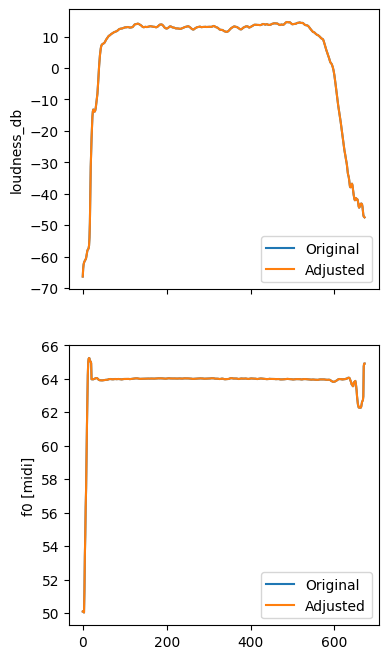

Original


Resynthesis


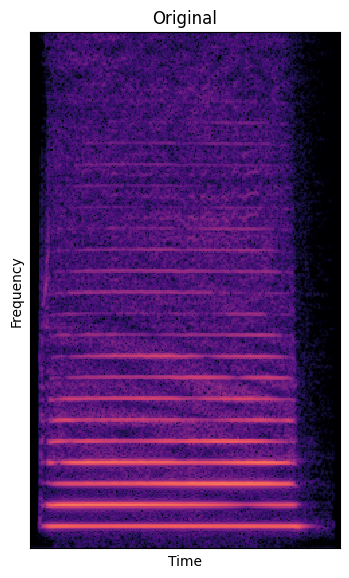

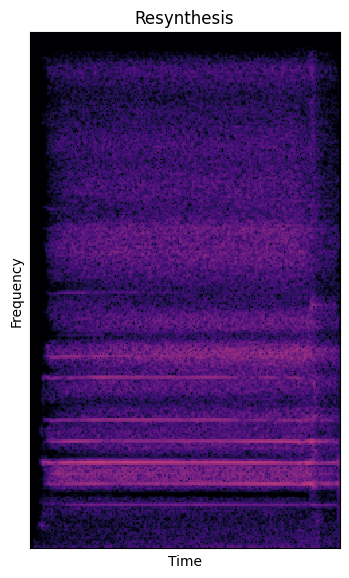

In [18]:
#@title # Step 5: Listen to Results

#@markdown Load and display the timbre transfer results.

import warnings
warnings.filterwarnings("ignore")

import base64
import io
import pickle

import numpy as np
import matplotlib.pyplot as plt
from IPython import display
from scipy.io import wavfile

SAMPLE_RATE = 16000


def play(array_of_floats, sample_rate=SAMPLE_RATE):
  if len(array_of_floats.shape) == 2:
    array_of_floats = array_of_floats[0]
  normalizer = float(np.iinfo(np.int16).max)
  array_of_ints = np.array(
      np.asarray(array_of_floats) * normalizer, dtype=np.int16)
  memfile = io.BytesIO()
  wavfile.write(memfile, sample_rate, array_of_ints)
  html = """<audio controls>
              <source controls src="data:audio/wav;base64,{base64_wavfile}"
              type="audio/wav" />
              Your browser does not support the audio element.
            </audio>"""
  html = html.format(
      base64_wavfile=base64.b64encode(memfile.getvalue()).decode('ascii'))
  memfile.close()
  display.display(display.HTML(html))


def specplot(audio, vmin=-5, vmax=1, rotate=True, size=512 + 256):
  if len(audio.shape) == 2:
    audio = audio[0]
  from scipy import signal as scipy_signal
  f, t, Sxx = scipy_signal.stft(audio, fs=SAMPLE_RATE, nperseg=size,
                                 noverlap=size * 3 // 4)
  logmag = np.log10(np.abs(Sxx) + 1e-7)
  if rotate:
    logmag = np.flipud(logmag)
  plt.matshow(logmag, vmin=vmin, vmax=vmax, cmap=plt.cm.magma, aspect='auto')
  plt.xticks([])
  plt.yticks([])
  plt.xlabel('Time')
  plt.ylabel('Frequency')


# Load outputs
audio_gen = np.load('/content/output/audio_gen.npy')
audio_orig = np.load('/content/output/audio_orig.npy')

with open('/content/output/plot_data.pkl', 'rb') as f:
  plot_data = pickle.load(f)

# --- Feature Plots ---
import librosa

TRIM = -15
mask_on = plot_data.get('mask_on')
has_mask = mask_on is not None and np.any(mask_on)
n_plots = 3 if has_mask else 2

fig, axes = plt.subplots(nrows=n_plots, ncols=1, sharex=True,
                         figsize=(2*n_plots, 8))

if has_mask:
  note_on_value = plot_data['note_on_value']
  ax = axes[0]
  ax.plot(np.ones_like(mask_on[:TRIM]) * 1.0, 'k:')
  ax.plot(note_on_value[:TRIM])
  ax.plot(mask_on[:TRIM])
  ax.set_ylabel('Note-on Mask')
  ax.set_xlabel('Time step [frame]')
  ax.legend(['Threshold', 'Likelihood', 'Mask'])

offset = 1 if has_mask else 0

ax = axes[0 + offset]
ax.plot(plot_data['loudness_db_orig'][:TRIM])
ax.plot(plot_data['loudness_db_mod'][:TRIM])
ax.set_ylabel('loudness_db')
ax.legend(['Original', 'Adjusted'])

ax = axes[1 + offset]
try:
  ax.plot(librosa.hz_to_midi(plot_data['f0_hz_orig'][:TRIM]))
  ax.plot(librosa.hz_to_midi(plot_data['f0_hz_mod'][:TRIM]))
except:
  ax.plot(plot_data['f0_hz_orig'][:TRIM])
  ax.plot(plot_data['f0_hz_mod'][:TRIM])
ax.set_ylabel('f0 [midi]')
_ = ax.legend(['Original', 'Adjusted'])
plt.show()

# --- Audio Playback ---
print('Original')
play(audio_orig)

print('Resynthesis')
play(audio_gen)

# --- Spectrograms ---
specplot(audio_orig)
plt.title('Original')
plt.show()

specplot(audio_gen)
_ = plt.title('Resynthesis')
plt.show()